# Radar Docente: prevendo a instabilidade do corpo docente nas escolas públicas de São Paulo

**Global Solution FIAP 2026.2, turma 2TSCOA. Tema CitizenTech: Data Science a serviço do cidadão.**
ODS 4 (meta 4.c, professores qualificados) e ODS 10 (redução das desigualdades).

## 1. O problema

**Cenário.** Em muitas escolas públicas, o aluno troca de professor todo ano, ou passa semanas sem aula de alguma disciplina enquanto a vaga não é preenchida. A rotatividade alta do corpo docente quebra a continuidade pedagógica, enfraquece o vínculo entre professores e alunos e dificulta qualquer projeto de longo prazo da escola.

**Relevância.** O INEP mede isso com o **IRD (Indicador de Regularidade do Docente)**. Para cada professor da escola no ano *t*, o IRD dá uma nota de 0 a 5 pela permanência dele naquela escola nos últimos cinco anos. O IRD da escola é a média dessas notas. Em 2025, cerca de **12% das escolas públicas paulistas estavam na faixa de baixa regularidade (IRD < 2)**. A rede estadual (IRD médio 2,58) é mais instável que a municipal (2,93).

**Quem é impactado.** Em primeiro lugar, o aluno de escola pública, sobretudo nas escolas mais vulneráveis. Também os professores (sobrecarga, contratos temporários) e os gestores, que só descobrem o problema depois que ele aconteceu.

**Como os dados apoiam a decisão.** O IRD publicado é um retrato do passado. O **Radar Docente** usa os indicadores do ano *t* para estimar **quais escolas vão estar em baixa regularidade no ano *t+1***. Com isso, a secretaria de educação pode agir antes: priorizar concursos e a alocação de efetivos, criar incentivos de permanência e reduzir contratos temporários onde o risco é maior.

**Ligação com o pitch.** *O INEP mostra onde o problema já aconteceu; o Radar mostra onde vai acontecer.* Este notebook é o motor de previsão por trás do mapa de risco por escola e município apresentado no pitch. O usuário é o(a) gestor(a) da secretaria de educação.

In [ ]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

CINZA, AZUL, LARANJA, AQUA = "#8a8984", "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, GRADE = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
    "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

## 2. Carregamento e descrição do dataset

**Fonte:** INEP, Indicadores Educacionais por escola (Censo Escolar e Saeb), em planilhas `.xlsx` de download público:

| Indicador | Arquivos | Uso |
|---|---|---|
| IRD: Regularidade do Corpo Docente | `IRD_ESCOLAS_2021..2025` | features `ird_t`, `ird_t_1`, `delta_ird`, `pct_baixa_mun_t` e **alvo** |
| AFD: Adequação da Formação Docente | `AFD_ESCOLAS_2022..2025` | `afd_g1_*` |
| IED: Esforço Docente | `IED_ESCOLAS_2022..2025` | `ied_alto_*` |
| ICG: Complexidade de Gestão | `ICG_ESCOLAS_2022..2025` | `icg` |
| ATU: Média de Alunos por Turma | `ATU_ESCOLAS_2022..2025` | `atu_*` |
| Taxas de Rendimento | `tx_rend_escolas_2022..2025` | `reprov_*`, `aband_*` |
| INSE 2023 (Saeb) | `INSE_2023_escolas` | **só para a auditoria de viés** |

**Origem e acesso aos dados originais.** Todas as planilhas estão disponíveis publicamente na página de **Indicadores Educacionais** do INEP, na seção "Educação Básica":
<https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/indicadores-educacionais>

- **Período:** indicadores de **2022 a 2025**. O IRD também usa **2021**, como lag do ano-base 2022, e o INSE é de **2023** (último disponível por escola).
- **Nomes na página do INEP:** "Regularidade do Corpo Docente" (IRD), "Adequação da Formação Docente" (AFD), "Esforço Docente" (IED), "Complexidade de Gestão da Escola" (ICG), "Média de Alunos por Turma" (ATU), "Taxas de Rendimento" e "Nível Socioeconômico (Inse)". Em todos, usamos o arquivo **por escola**.
- **Download:** novembro de 2026.
- **Reconstrução da base:** as planilhas originais (~600 MB) não vão no `.zip`. Para auditar a montagem, basta baixá-las para a pasta `data/` e rodar `python src/build_dataset.py`, que gera de novo os CSVs usados neste notebook.

> **Atenção aos nomes dos arquivos.** O INEP pode mudar o nome dos arquivos no site (isso aconteceu uma vez durante o desenvolvimento deste projeto). O script procura os arquivos pelo nome, então pode ser necessário **renomear as planilhas baixadas** para o padrão abaixo, em que `{ano}` é o ano com quatro dígitos:
>
> | Indicador | Nome esperado em `data/` | Anos |
> |---|---|---|
> | Regularidade do Corpo Docente (IRD) | `IRD_ESCOLAS_{ano}.xlsx` | 2021 a 2025 |
> | Adequação da Formação Docente (AFD) | `AFD_ESCOLAS_{ano}.xlsx` | 2022 a 2025 |
> | Esforço Docente (IED) | `IED_ESCOLAS_{ano}.xlsx` | 2022 a 2025 |
> | Complexidade de Gestão da Escola (ICG) | `ICG_ESCOLAS_{ano}.xlsx` | 2022 a 2025 |
> | Média de Alunos por Turma (ATU) | `ATU_ESCOLAS_{ano}.xlsx` | 2022 a 2025 |
> | Taxas de Rendimento | `tx_rend_escolas_{ano}.xlsx` | 2022 a 2025 |
> | Nível Socioeconômico (INSE) | `INSE_2023_escolas.xlsx` | 2023 |
>
> Exemplo: `IRD_ESCOLAS_2024.xlsx`. Os arquivos precisam estar em formato `.xlsx`. Se o INEP distribuir algum indicador compactado (`.zip`), é preciso extrair a planilha antes de renomear.

As planilhas do INEP têm linhas de título no topo, rodapé com "Fonte:" e "Notas:" e valores como `--` (etapa não oferecida) no lugar de números. O script `src/build_dataset.py` (enviado junto no `.zip`) faz a limpeza e monta a base única `data/base_radar_docente.csv`. Os arquivos de 2025 dos indicadores não entram no treino nem no teste: servem só para a previsão de 2026 do anexo (seção 12), em `data/base_previsao_2025.csv`. Os passos da montagem são:

1. localiza a linha de cabeçalho com códigos (`NU_ANO_CENSO`, `CO_ENTIDADE`...) em cada arquivo;
2. remove o rodapé, lê os códigos de escola e município como texto e converte `--`/`*` em `NaN`;
3. filtra **SP** e as redes **Municipal e Estadual**;
4. para cada ano-base *t* ∈ {2022, 2023, 2024}, junta o IRD de *t-1*, *t* e *t+1* com os indicadores de *t*;
5. mantém só as escolas **com IRD em t e em t+1** e que oferecem **Ensino Fundamental e/ou Médio**. As escolas só de Educação Infantil ficam fora, porque nelas o esforço docente e o rendimento não existem. A escola "oferece" uma etapa quando tem turmas (ATU) ou taxas de rendimento naquela etapa: são os dados que refletem se há alunos matriculados, e não um indicador isolado de docentes.

**Unidade de análise:** uma linha = uma escola em um ano-base *t*.

| ano_base | features de | lag de | alvo de | conjunto |
|---|---|---|---|---|
| 2022 | 2022 | 2021 | 2023 | treino |
| 2023 | 2023 | 2022 | 2024 | treino |
| 2024 | 2024 | 2023 | 2025 | **teste** |

In [ ]:
DATA = Path("data")
CSV = DATA / "base_radar_docente.csv"
if not CSV.exists():
    sys.path.insert(0, "src")
    import build_dataset
    build_dataset.main()

base = pd.read_csv(CSV, dtype={"co_escola": str, "co_municipio": str})
print(f"{base.shape[0]:,} linhas x {base.shape[1]} colunas | "
      f"{base['co_escola'].nunique():,} escolas | {base['co_municipio'].nunique()} municípios")
base.head()

32,909 linhas x 28 colunas | 11,119 escolas | 645 municípios


,ano_base,co_escola,no_escola,co_municipio,no_municipio,rede,localizacao,ird_t,ird_t_1,delta_ird,pct_baixa_mun_t,afd_g1_fun,afd_g1_med,ied_alto_fun,ied_alto_med,icg,atu_fun,atu_med,reprov_fun,reprov_med,aband_fun,aband_med,tem_fundamental,tem_medio,inse_media,inse_classe,ird_t1,alvo
0,2022,35030806,HELEN KELLER,3500105,Adamantina,Estadual,Urbana,2.499,2.300,0.199,0.000,62.000,57.100,24.300,32.700,5.000,31.100,30.900,0.000,0.600,0.000,0.000,1,1,5.400,Nível V,2.643,0
1,2022,35031045,DURVALINO GRION PROF,3500105,Adamantina,Estadual,Urbana,2.638,2.700,-0.062,0.000,58.700,NaN,15.800,NaN,2.000,34.000,NaN,0.900,NaN,0.000,NaN,1,0,5.440,Nível V,2.576,0
2,2022,35031082,EUDECIO LUIZ VICENTE PROF ETEC,3500105,Adamantina,Estadual,Urbana,3.699,3.800,-0.101,0.000,NaN,47.700,NaN,74.200,4.000,NaN,35.600,NaN,0.600,NaN,0.000,0,1,5.760,Nível VI,3.691,0
3,2022,35031100,HERVAL BELLUSCI ENGENHEIRO ETEC,3500105,Adamantina,Estadual,Rural,3.351,3.200,0.151,0.000,NaN,26.700,NaN,78.500,4.000,NaN,28.300,NaN,0.000,NaN,0.000,0,1,5.470,Nível V,3.310,0
4,2022,35031112,FLEURIDES CAVALLINI MENECHINO PROFA,3500105,Adamantina,Estadual,Urbana,2.639,2.900,-0.261,0.000,67.000,48.400,8.000,10.000,2.000,33.100,25.300,0.000,2.600,0.300,0.600,1,1,5.430,Nível V,2.868,0


### Variável-alvo e variáveis preditoras

- **Alvo (`alvo`)**: `1` se a escola estiver em **baixa regularidade docente no ano seguinte**, ou seja, `IRD(t+1) < 2` (faixa oficial do INEP); `0` caso contrário.
- **`ird_t1`** (IRD em *t+1*) é a **origem do alvo**. Fica na base só para conferência e **é excluída das features** para não haver vazamento.
- **Preditoras**: todas medidas no ano *t* ou antes, conforme o dicionário abaixo.

In [3]:
dicionario = pd.DataFrame([
    ("ird_t", "IRD da escola no ano t (0 a 5)", "IRD", "preditora"),
    ("ird_t_1", "IRD da escola no ano t-1", "IRD", "preditora"),
    ("delta_ird", "ird_t - ird_t_1 (tendência recente)", "IRD", "preditora"),
    ("pct_baixa_mun_t", "% de escolas municipais e estaduais do município com IRD < 2 em t", "IRD (por escola)", "preditora"),
    ("rede", "Municipal ou Estadual", "Censo", "preditora"),
    ("localizacao", "Urbana ou Rural", "Censo", "preditora"),
    ("afd_g1_fun / afd_g1_med", "% de docentes com formação adequada à disciplina (grupo 1), EF / EM", "AFD", "preditora"),
    ("ied_alto_fun / ied_alto_med", "% de docentes com esforço alto (níveis 4 a 6), EF / EM", "IED", "preditora"),
    ("icg", "Complexidade de gestão (nível 1 a 6)", "ICG", "preditora"),
    ("atu_fun / atu_med", "Média de alunos por turma, EF / EM", "ATU", "preditora"),
    ("reprov_fun / reprov_med", "Taxa de reprovação (%), EF / EM", "Rendimento", "preditora"),
    ("aband_fun / aband_med", "Taxa de abandono (%), EF / EM", "Rendimento", "preditora"),
    ("tem_fundamental / tem_medio", "A escola oferece EF / EM (0/1): tem valor da etapa em ATU ou Rendimento", "derivada", "preditora"),
    ("inse_media / inse_classe", "Nível socioeconômico dos alunos (Saeb 2023)", "INSE", "só auditoria de viés"),
    ("ird_t1", "IRD em t+1", "IRD", "origem do alvo (excluída)"),
    ("alvo", "1 se ird_t1 < 2", "derivada", "ALVO"),
], columns=["variável", "descrição", "fonte", "papel"])
dicionario.style.hide(axis="index")

variável,descrição,fonte,papel
ird_t,IRD da escola no ano t (0 a 5),IRD,preditora
ird_t_1,IRD da escola no ano t-1,IRD,preditora
delta_ird,ird_t - ird_t_1 (tendência recente),IRD,preditora
pct_baixa_mun_t,% de escolas municipais e estaduais do município com IRD < 2 em t,IRD (por escola),preditora
rede,Municipal ou Estadual,Censo,preditora
localizacao,Urbana ou Rural,Censo,preditora
afd_g1_fun / afd_g1_med,"% de docentes com formação adequada à disciplina (grupo 1), EF / EM",AFD,preditora
ied_alto_fun / ied_alto_med,"% de docentes com esforço alto (níveis 4 a 6), EF / EM",IED,preditora
icg,Complexidade de gestão (nível 1 a 6),ICG,preditora
atu_fun / atu_med,"Média de alunos por turma, EF / EM",ATU,preditora


## 3. Análise exploratória

### 3.1 Distribuição do alvo
A classe positiva é **rara**, entre 6% e 9% das escolas por ano, e vem crescendo. Com essa proporção, a acurácia sozinha engana: um modelo que sempre responde "sem risco" teria cerca de 92% de acerto e não encontraria nenhuma escola em risco.

In [4]:
resumo_alvo = (base.groupby("ano_base")["alvo"]
               .agg(escolas="size", em_risco="sum", taxa="mean")
               .assign(conjunto=lambda d: np.where(d.index == 2024, "teste", "treino")))
resumo_alvo

,escolas,em_risco,taxa,conjunto
ano_base,,,,
2022,10997,627,0.057,treino
2023,10972,841,0.077,treino
2024,10940,987,0.090,teste


### 3.2 O IRD é persistente
O gráfico abaixo mostra o IRD em *t* contra o IRD em *t+1*. A maior parte das escolas fica perto da diagonal, então **o IRD atual é o melhor preditor isolado do próximo**. Por isso o **baseline obrigatório** é a regra simples "prever risco se `ird_t < 2`". Os modelos só se justificam se acharem as escolas que **cruzam** a linha de 2 (quadrante superior esquerdo → inferior direito e vice-versa).

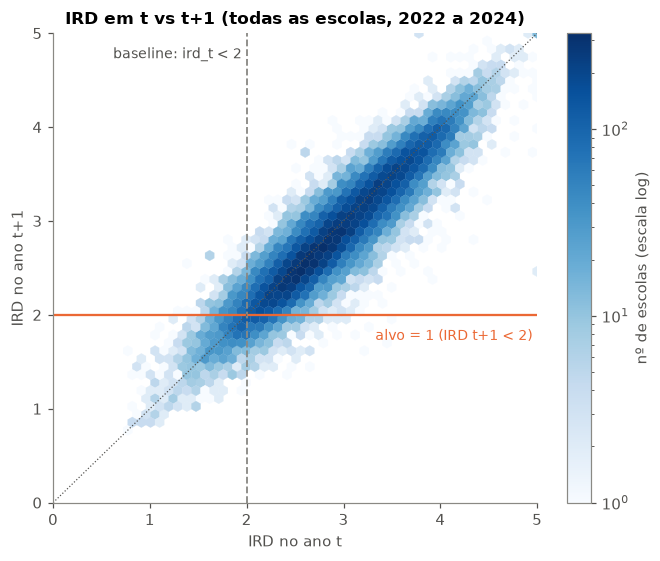

,alvo=0,alvo=1,Total
IRD t ≥ 2,29886,894,30780
IRD t < 2,568,1561,2129
Total,30454,2455,32909


In [5]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
hb = ax.hexbin(base["ird_t"], base["ird_t1"], gridsize=45, cmap="Blues", mincnt=1, bins="log",
               linewidths=0.2)
ax.axhline(2, color=LARANJA, lw=1.5); ax.axvline(2, color=CINZA, lw=1.2, ls="--")
ax.plot([0, 5], [0, 5], color=TEXTO_2, lw=0.8, ls=":")
ax.set(xlabel="IRD no ano t", ylabel="IRD no ano t+1", xlim=(0, 5), ylim=(0, 5),
       title="IRD em t vs t+1 (todas as escolas, 2022 a 2024)")
ax.text(4.95, 1.85, "alvo = 1 (IRD t+1 < 2)", ha="right", va="top", color=LARANJA, fontsize=9)
ax.text(1.95, 4.85, "baseline: ird_t < 2", ha="right", va="top", color=TEXTO_2, fontsize=9)
ax.grid(False)
fig.colorbar(hb, ax=ax, label="nº de escolas (escala log)")
plt.tight_layout(); plt.show()

cruz = pd.crosstab(base["ird_t"] < 2, base["alvo"], margins=True)
cruz.index = ["IRD t ≥ 2", "IRD t < 2", "Total"]; cruz.columns = ["alvo=0", "alvo=1", "Total"]
cruz

### 3.3 Taxa de risco por rede e localização
A rede **estadual** e as escolas **rurais** têm taxas de risco bem maiores. Isso confirma o diagnóstico do pitch e também acende um alerta para a auditoria de viés (seção 9).

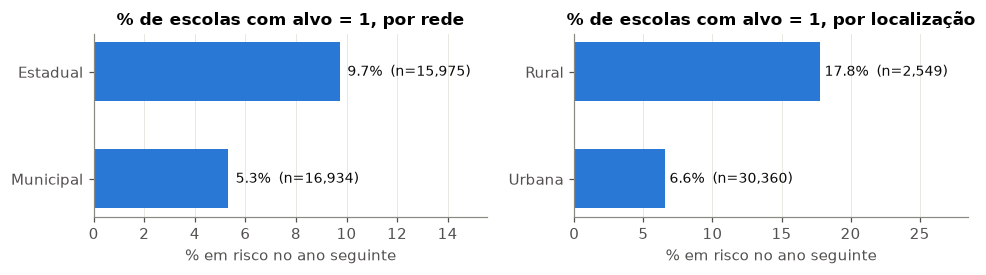

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
for ax, col, rotulo in zip(axes, ["rede", "localizacao"], ["rede", "localização"]):
    taxa = base.groupby(col)["alvo"].agg(["mean", "size"]).sort_values("mean")
    bars = ax.barh(taxa.index, taxa["mean"] * 100, color=AZUL, height=0.55)
    for b, (m, n) in zip(bars, taxa.values):
        ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2,
                f"{m*100:.1f}%  (n={int(n):,})", va="center", color=TEXTO, fontsize=9)
    ax.set(title=f"% de escolas com alvo = 1, por {rotulo}", xlabel="% em risco no ano seguinte")
    ax.set_xlim(0, taxa["mean"].max() * 100 * 1.6); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 3.4 Indicadores por etapa e o caso do abandono no Fundamental
AFD, IED, ATU e Rendimento vêm **separados por etapa** (Fundamental e Médio), e nenhuma coluna é um total da escola. Por isso cada indicador vira duas features (`_fun` e `_med`). Uma dúvida era se o **abandono no Fundamental** seria quase sempre zero e, portanto, inútil. A tabela abaixo (ano 2024, escolas com valor) mostra que ele é baixo, mas **não** é "quase sempre zero": cerca de 42% das escolas têm abandono positivo. Por isso a feature foi mantida, e a importância das features (seção 8) mostra depois se ela contribui.

In [7]:
def resumo_taxa(s):
    s = s.dropna()
    return pd.Series({"escolas com valor": len(s), "% igual a 0": (s == 0).mean() * 100,
                      "média (%)": s.mean(), "p90 (%)": s.quantile(0.9)})

b24 = base[base["ano_base"] == 2024]
pd.DataFrame({"abandono EF": resumo_taxa(b24["aband_fun"]),
              "reprovação EF": resumo_taxa(b24["reprov_fun"]),
              "abandono EM": resumo_taxa(b24["aband_med"]),
              "reprovação EM": resumo_taxa(b24["reprov_med"])}).T

,escolas com valor,% igual a 0,média (%),p90 (%)
abandono EF,10195.000,57.636,0.435,1.300
reprovação EF,10195.000,46.817,1.201,3.600
abandono EM,3987.000,26.411,2.418,6.100
reprovação EM,3987.000,28.894,2.739,7.400


In [8]:
NUM_IND = ["ird_t", "delta_ird", "pct_baixa_mun_t", "afd_g1_fun", "ied_alto_fun", "icg",
           "atu_fun", "reprov_fun", "aband_fun", "aband_med"]
comp = base.groupby("alvo")[NUM_IND].median().T
comp.columns = ["mediana alvo=0", "mediana alvo=1"]
comp

,mediana alvo=0,mediana alvo=1
ird_t,2.942,1.915
delta_ird,-0.020,-0.154
pct_baixa_mun_t,4.839,11.111
afd_g1_fun,80.400,75.000
ied_alto_fun,37.600,41.250
icg,3.000,3.000
atu_fun,26.900,25.800
reprov_fun,0.300,0.000
aband_fun,0.000,0.000
aband_med,1.600,2.100


## 4. Pré-processamento

**Já feito na montagem da base** (`src/build_dataset.py`): limpeza de cabeçalho e rodapé, códigos como texto, `--`/`*` → `NaN`, filtros de UF, rede e universo, e cálculo das features derivadas (`delta_ird`, `ied_alto` = soma dos níveis 4 a 6, `icg` ordinal, `pct_baixa_mun_t`). São transformações **linha a linha ou agregações do próprio ano *t***, sem nenhum parâmetro estimado a partir do alvo ou do conjunto de teste.

**Valores ausentes: dois tipos, dois tratamentos.**

In [9]:
FUN = ["afd_g1_fun", "ied_alto_fun", "atu_fun", "reprov_fun", "aband_fun"]
MED = ["afd_g1_med", "ied_alto_med", "atu_med", "reprov_med", "aband_med"]

ausentes = pd.DataFrame({
    "% ausente (total)": base[FUN + MED + ["ird_t_1"]].isna().mean() * 100,
    "% ausente quando a etapa É oferecida": pd.concat([
        base.loc[base["tem_fundamental"] == 1, FUN].isna().mean(),
        base.loc[base["tem_medio"] == 1, MED].isna().mean(),
        pd.Series({"ird_t_1": base["ird_t_1"].isna().mean()})]) * 100,
})
ausentes

,% ausente (total),% ausente quando a etapa É oferecida
afd_g1_fun,6.822,0.003
ied_alto_fun,6.819,0.000
atu_fun,6.828,0.010
reprov_fun,6.825,0.007
aband_fun,6.825,0.007
afd_g1_med,63.575,0.008
ied_alto_med,63.560,0.000
atu_med,63.572,0.000
reprov_med,63.575,0.008
aband_med,63.575,0.008


- **Ausentes estruturais** (a escola não oferece a etapa, por exemplo `_med` numa escola só de Fundamental): são a grande maioria (~64% nas colunas de Médio). Imputar média ou mediana inventaria um Ensino Médio que não existe. Por isso esses valores recebem a **constante 0**, e as flags `tem_fundamental` / `tem_medio` separam o "0 real" (por exemplo, 0% de abandono) da "etapa inexistente": a Random Forest pode dividir pela flag, e na Regressão Logística o coeficiente da flag absorve a diferença. O −1 também funcionaria; escolhemos o 0 por simplicidade, já que, com a flag no modelo, o valor exato da constante pouco importa. O preenchimento é feito dentro do Pipeline, e o CSV guarda os valores originais (vazios).
- **Ausentes aleatórios** (a etapa é oferecida, mas o valor está faltando, menos de 0,5%), mais o `ird_t_1` ausente de escolas novas: **imputação pela mediana**, ajustada **dentro do Pipeline**, ou seja, só com os dados de treino de cada fold.
- **Categóricas** (`rede`, `localizacao`): one-hot.
- **Escala**: `StandardScaler` só na Regressão Logística, que é sensível à escala. A Random Forest não precisa.

Todas essas etapas ficam dentro de um `Pipeline` do scikit-learn. Assim, na validação cruzada e no teste, a imputação e a padronização são **ajustadas apenas no treino**, sem vazamento.

In [ ]:
NUM_FEATS = ["ird_t", "ird_t_1", "delta_ird", "pct_baixa_mun_t", "icg"] + FUN + MED + \
            ["tem_fundamental", "tem_medio"]
CAT_FEATS = ["rede", "localizacao"]
FEATURES = NUM_FEATS + CAT_FEATS
ALVO = "alvo"
assert "ird_t1" not in FEATURES and ALVO not in FEATURES and "inse_media" not in FEATURES

CONST_ESTRUTURAL = 0


def preencher_estruturais(X):
    X = X.copy()
    X.loc[X["tem_fundamental"] == 0, FUN] = CONST_ESTRUTURAL
    X.loc[X["tem_medio"] == 0, MED] = CONST_ESTRUTURAL
    return X


def montar_pipeline(modelo, escalar):
    passos_num = [("imputa", SimpleImputer(strategy="median"))]
    if escalar:
        passos_num.append(("escala", StandardScaler()))
    prep = ColumnTransformer([
        ("num", Pipeline(passos_num), NUM_FEATS),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CAT_FEATS),
    ], verbose_feature_names_out=False)
    return Pipeline([("estruturais", FunctionTransformer(preencher_estruturais)),
                     ("prep", prep), ("modelo", modelo)])

## 5. Divisão treino/teste temporal e validação cruzada

- **Treino:** anos-base 2022 e 2023 (alvos de 2023 e 2024). **Teste:** ano-base 2024 (alvo de 2025). A ordem cronológica é respeitada: o modelo nunca vê o futuro que vai prever, que é exatamente a situação real de uso (treinar com o passado e prever o próximo ano).
- **Validação cruzada só no treino**, com **`GroupKFold` por escola**. A mesma escola aparece em 2022 e em 2023. Sem o agrupamento, a escola estaria no treino e na validação ao mesmo tempo, e o desempenho na validação sairia otimista.
- O conjunto de teste só é usado **uma vez**, no fim, com o modelo e o limiar já escolhidos.

In [11]:
treino = base[base["ano_base"].isin([2022, 2023])].reset_index(drop=True)
teste = base[base["ano_base"] == 2024].reset_index(drop=True)

X_tr, y_tr, grupos_tr = treino[FEATURES], treino[ALVO], treino["co_escola"]
X_te, y_te = teste[FEATURES], teste[ALVO]
cv = GroupKFold(n_splits=5)

pd.DataFrame({"linhas": [len(treino), len(teste)],
              "escolas": [treino["co_escola"].nunique(), teste["co_escola"].nunique()],
              "% alvo=1": [y_tr.mean() * 100, y_te.mean() * 100]},
             index=["treino (2022-23)", "teste (2024)"])

,linhas,escolas,% alvo=1
treino (2022-23),21969,11066,6.682
teste (2024),10940,10940,9.022


## 6. Baseline: "a escola continua como está"

A regra mais simples que um gestor usaria hoje com o dado público do INEP: **marcar como risco toda escola que já está com IRD < 2**. Ela não aprende nada e serve de régua: os modelos precisam superá-la para justificar a complexidade.

In [12]:
def metricas(y, pred, proba=None):
    m = {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
         "Recall": recall_score(y, pred), "F1": f1_score(y, pred)}
    m["PR-AUC"] = average_precision_score(y, proba) if proba is not None else np.nan
    m["Alertas"] = int(np.sum(pred))
    return m

baseline_tr = (treino["ird_t"] < 2).astype(int)
baseline_te = (teste["ird_t"] < 2).astype(int)
pd.DataFrame({"Baseline, treino (2022-23)": metricas(y_tr, baseline_tr),
              "Baseline, teste (2024)": metricas(y_te, baseline_te)}).T

,Accuracy,Precision,Recall,F1,PR-AUC,Alertas
"Baseline, treino (2022-23)",0.958,0.710,0.623,0.664,NaN,1289.000
"Baseline, teste (2024)",0.951,0.769,0.655,0.707,NaN,840.000


## 7. Modelos supervisionados

Dois modelos de natureza diferente:

1. **Regressão Logística**: linear, interpretável (coeficientes), boa referência de modelo "transparente" para gestão pública.
2. **Random Forest**: não linear, captura interações (por exemplo, IRD perto de 2 **e** tendência de queda **e** município instável).

Ambos usam `class_weight="balanced"` por causa do desbalanceamento. Os hiperparâmetros são escolhidos com `GridSearchCV` + `GroupKFold` **só no treino**, pela métrica **PR-AUC** (*average precision*), que não depende do limiar e é adequada para a classe rara.

**Escolha do limiar.** Um modelo probabilístico não decide sozinho onde fica o corte entre "risco" e "sem risco". O limiar é escolhido nas **previsões *out-of-fold*** da validação cruzada (de novo, só no treino), maximizando o **F1 da classe 1**. A seção 8.4 discute um modo alternativo, de alta sensibilidade.

In [13]:
modelos = {
    "Regressão Logística": GridSearchCV(
        montar_pipeline(LogisticRegression(class_weight="balanced", max_iter=3000), escalar=True),
        {"modelo__C": [0.01, 0.1, 1, 10]},
        cv=cv, scoring="average_precision", n_jobs=-1),
    "Random Forest": GridSearchCV(
        montar_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                               random_state=RANDOM_STATE, n_jobs=-1), escalar=False),
        {"modelo__min_samples_leaf": [5, 20], "modelo__max_features": ["sqrt", 0.5],
         "modelo__max_depth": [12, None]},
        cv=cv, scoring="average_precision", n_jobs=1),
}

for nome, gs in modelos.items():
    gs.fit(X_tr, y_tr, groups=grupos_tr)
    print(f"{nome:20s} melhor PR-AUC (CV) = {gs.best_score_:.3f} | {gs.best_params_}")

Regressão Logística  melhor PR-AUC (CV) = 0.733 | {'modelo__C': 0.01}


Random Forest        melhor PR-AUC (CV) = 0.753 | {'modelo__max_depth': None, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 5}


In [14]:
LIMIARES = np.round(np.arange(0.05, 0.96, 0.01), 2)

def limiar_max_f1(y, proba):
    f1s = [f1_score(y, proba >= t, zero_division=0) for t in LIMIARES]
    return LIMIARES[int(np.argmax(f1s))]

oof, limiar = {}, {}
for nome, gs in modelos.items():
    oof[nome] = cross_val_predict(gs.best_estimator_, X_tr, y_tr, groups=grupos_tr, cv=cv,
                                  method="predict_proba")[:, 1]
    limiar[nome] = limiar_max_f1(y_tr, oof[nome])

cv_tab = {"Baseline (IRD_t < 2)": metricas(y_tr, baseline_tr)}
for nome in modelos:
    cv_tab[nome] = metricas(y_tr, (oof[nome] >= limiar[nome]).astype(int), oof[nome])
cv_tab = pd.DataFrame(cv_tab).T.assign(limiar=pd.Series(limiar))
print("Validação cruzada (GroupKFold por escola, previsões out-of-fold no TREINO):")
cv_tab

Validação cruzada (GroupKFold por escola, previsões out-of-fold no TREINO):


,Accuracy,Precision,Recall,F1,PR-AUC,Alertas,limiar
Baseline (IRD_t < 2),0.958,0.710,0.623,0.664,NaN,1289.000,NaN
Regressão Logística,0.952,0.618,0.736,0.672,0.735,1749.000,0.800
Random Forest,0.956,0.646,0.744,0.691,0.752,1691.000,0.520


## 8. Avaliação no conjunto de teste (ano-base 2024 → alvo 2025)

### 8.1 Métricas

In [15]:
NOMES = ["Baseline (IRD_t < 2)", "Regressão Logística", "Random Forest"]
COR = dict(zip(NOMES, [CINZA, AZUL, LARANJA]))

proba_te = {n: modelos[n].predict_proba(X_te)[:, 1] for n in modelos}
pred_te = {"Baseline (IRD_t < 2)": baseline_te.values}
pred_te.update({n: (proba_te[n] >= limiar[n]).astype(int) for n in modelos})

res = pd.DataFrame({n: metricas(y_te, pred_te[n], proba_te.get(n)) for n in NOMES}).T
res["limiar"] = pd.Series(limiar)
res

,Accuracy,Precision,Recall,F1,PR-AUC,Alertas,limiar
Baseline (IRD_t < 2),0.951,0.769,0.655,0.707,NaN,840.000,NaN
Regressão Logística,0.943,0.652,0.788,0.713,0.782,1194.000,0.800
Random Forest,0.946,0.674,0.774,0.721,0.795,1133.000,0.520


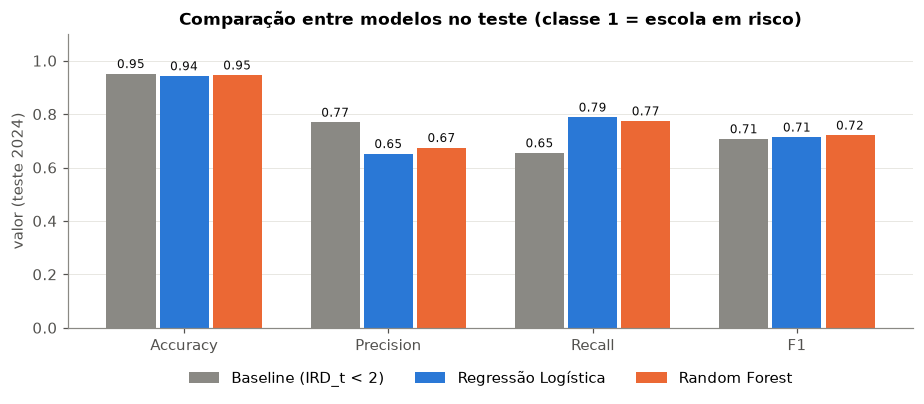

In [16]:
mets = ["Accuracy", "Precision", "Recall", "F1"]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
w = 0.26
x = np.arange(len(mets))
for i, n in enumerate(NOMES):
    vals = res.loc[n, mets].astype(float).values
    bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=COR[n], label=n)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom",
                fontsize=8, color=TEXTO)
ax.set_xticks(x, mets); ax.set_ylim(0, 1.1); ax.set_ylabel("valor (teste 2024)")
ax.set_title("Comparação entre modelos no teste (classe 1 = escola em risco)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 8.2 Matrizes de confusão
**Falso negativo** (FN) = escola que vai entrar em baixa regularidade e o Radar **não avisou**. **Falso positivo** (FP) = alerta para uma escola que acabou não entrando na faixa.

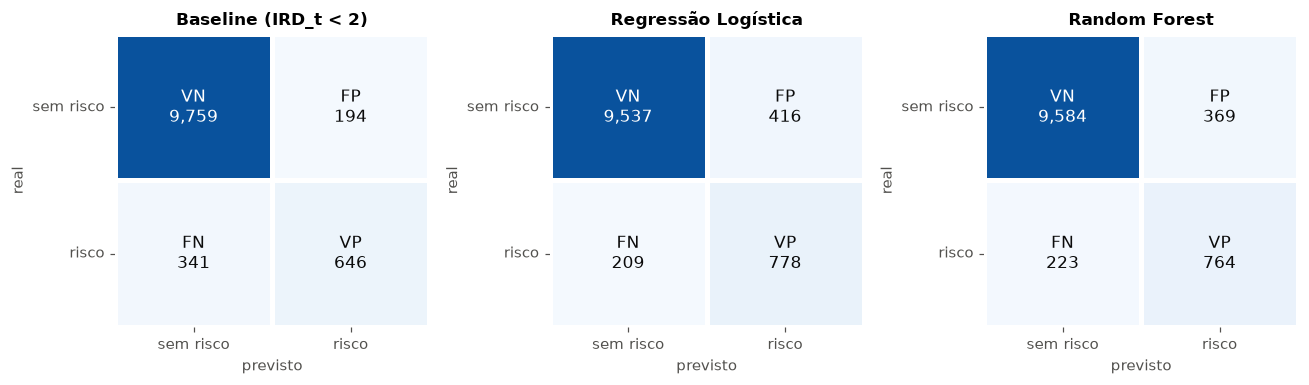

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, n in zip(axes, NOMES):
    cm = confusion_matrix(y_te, pred_te[n])
    sns.heatmap(cm, annot=False, cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white",
                vmin=0, vmax=cm.max() * 1.15)
    rot = [["VN", "FP"], ["FN", "VP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.5, f"{rot[i][j]}\n{cm[i, j]:,}", ha="center", va="center",
                    fontsize=11, color="white" if cm[i, j] > cm.max() * 0.5 else TEXTO)
    ax.set(title=n, xlabel="previsto", ylabel="real")
    ax.set_xticklabels(["sem risco", "risco"]); ax.set_yticklabels(["sem risco", "risco"], rotation=0)
plt.tight_layout(); plt.show()

**Onde a regra simples falha.** Por construção, o baseline nunca avisa uma escola que hoje está com IRD ≥ 2 e vai **cair** para baixo de 2. Ele também dispara alerta para escolas abaixo de 2 que vão **sair** da faixa. A tabela abaixo mostra como cada modelo se sai nesses dois grupos.

In [18]:
acima = (teste["ird_t"] >= 2).values
caem, saem = (y_te.values == 1) & acima, (y_te.values == 0) & ~acima
pd.DataFrame({n: {"caem para < 2 (n)": caem.sum(), "caem: avisadas": pred_te[n][caem].sum(),
                  "caem: recall": pred_te[n][caem].mean(),
                  "saem da faixa (n)": saem.sum(), "saem: alerta (FP)": pred_te[n][saem].sum()}
              for n in NOMES}).T

,caem para < 2 (n),caem: avisadas,caem: recall,saem da faixa (n),saem: alerta (FP)
Baseline (IRD_t < 2),341.000,0.000,0.000,194.000,194.000
Regressão Logística,341.000,133.000,0.390,194.000,192.000
Random Forest,341.000,120.000,0.352,194.000,189.000


### 8.3 Curva precisão × recall
A curva mostra todos os pontos de operação possíveis de cada modelo. O baseline é um **único ponto**: a regra "IRD < 2" não tem limiar ajustável. Quando a curva de um modelo passa **acima e à direita** do ponto do baseline, o modelo consegue mais recall com a mesma precisão (ou o contrário).

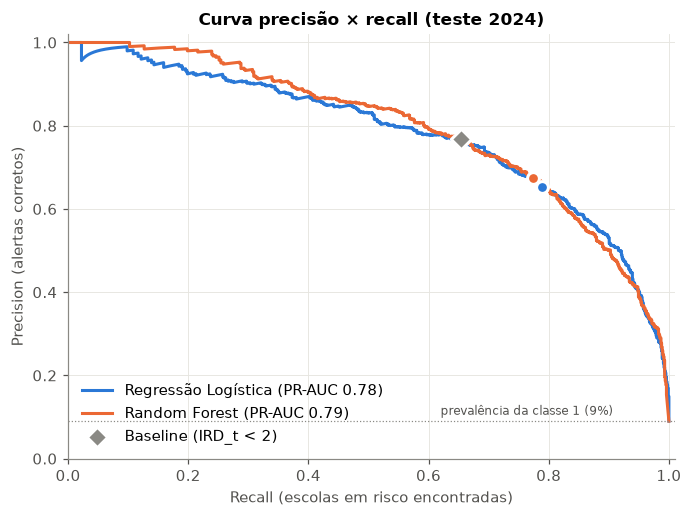

In [19]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
for n in modelos:
    p, r, t = precision_recall_curve(y_te, proba_te[n])
    ax.plot(r, p, color=COR[n], lw=2, label=f"{n} (PR-AUC {res.loc[n, 'PR-AUC']:.2f})")
    ax.scatter(res.loc[n, "Recall"], res.loc[n, "Precision"], s=60, color=COR[n],
               edgecolor="white", linewidth=2, zorder=3)
ax.scatter(res.loc[NOMES[0], "Recall"], res.loc[NOMES[0], "Precision"], s=90, marker="D",
           color=CINZA, edgecolor="white", linewidth=2, zorder=4, label="Baseline (IRD_t < 2)")
ax.axhline(y_te.mean(), color=CINZA, lw=0.8, ls=":")
ax.text(0.62, y_te.mean() + 0.015, f"prevalência da classe 1 ({y_te.mean():.0%})", color=TEXTO_2, fontsize=8)
ax.set(xlabel="Recall (escolas em risco encontradas)", ylabel="Precision (alertas corretos)",
       xlim=(0, 1.01), ylim=(0, 1.02), title="Curva precisão × recall (teste 2024)")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

### 8.4 Modo de alta sensibilidade
Para a secretaria, **deixar passar uma escola em risco custa mais que um alerta a mais**: o alerta desnecessário leva, no máximo, a uma visita ou a uma checagem de quadro, enquanto o falso negativo leva a um ano de aulas vagas. Por isso vale avaliar também um limiar escolhido (de novo, **no treino, *out-of-fold***) para garantir **recall ≥ 85%**, e ver quanto isso custa em alertas extras.

In [20]:
def limiar_para_recall(y, proba, alvo_recall=0.85):
    ok = [t for t in LIMIARES if recall_score(y, proba >= t) >= alvo_recall]
    return max(ok) if ok else LIMIARES[0]

sens = {}
for n in modelos:
    t = limiar_para_recall(y_tr, oof[n])
    sens[f"{n} (recall≥85%)"] = {**metricas(y_te, (proba_te[n] >= t).astype(int), proba_te[n]),
                                  "limiar": t}
pd.concat([res.loc[NOMES], pd.DataFrame(sens).T])

,Accuracy,Precision,Recall,F1,PR-AUC,Alertas,limiar
Baseline (IRD_t < 2),0.951,0.769,0.655,0.707,NaN,840.000,NaN
Regressão Logística,0.943,0.652,0.788,0.713,0.782,1194.000,0.800
Random Forest,0.946,0.674,0.774,0.721,0.795,1133.000,0.520
Regressão Logística (recall≥85%),0.917,0.523,0.901,0.662,0.782,1700.000,0.670
Random Forest (recall≥85%),0.916,0.519,0.884,0.654,0.795,1683.000,0.320


### 8.5 Importância das variáveis
Usamos a **importância por permutação** no conjunto de teste: quanto o PR-AUC piora quando embaralhamos cada variável. Ela vale para qualquer modelo e é mais confiável que a importância por impureza da Random Forest, que favorece variáveis contínuas. Os **coeficientes da Regressão Logística** (variáveis padronizadas) mostram a **direção** do efeito.

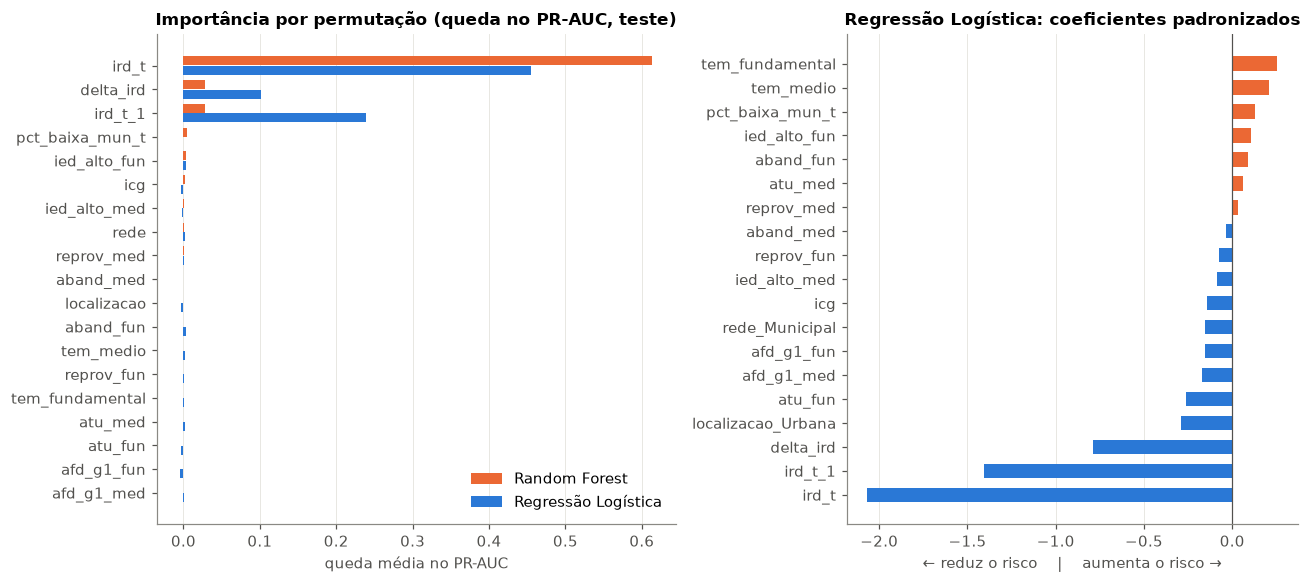

,Regressão Logística,Random Forest
ird_t,0.455,0.613
delta_ird,0.102,0.029
ird_t_1,0.239,0.028
pct_baixa_mun_t,-0.001,0.005
ied_alto_fun,0.004,0.003
icg,-0.004,0.002
ied_alto_med,-0.002,0.001
rede,0.003,0.000


In [21]:
imp = {}
for n in modelos:
    r = permutation_importance(modelos[n].best_estimator_, X_te, y_te, scoring="average_precision",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp[n] = pd.Series(r.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp).sort_values("Random Forest")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
y = np.arange(len(imp))
ax.barh(y + 0.2, imp["Random Forest"], 0.38, color=LARANJA, label="Random Forest")
ax.barh(y - 0.2, imp["Regressão Logística"], 0.38, color=AZUL, label="Regressão Logística")
ax.set_yticks(y, imp.index); ax.grid(axis="y", visible=False)
ax.set(title="Importância por permutação (queda no PR-AUC, teste)", xlabel="queda média no PR-AUC")
ax.legend(loc="lower right")

lr = modelos["Regressão Logística"].best_estimator_
coef = pd.Series(lr.named_steps["modelo"].coef_[0],
                 index=lr.named_steps["prep"].get_feature_names_out()).sort_values()
ax = axes[1]
ax.barh(coef.index, coef.values, color=[AZUL if v < 0 else LARANJA for v in coef.values], height=0.6)
ax.axvline(0, color=TEXTO_2, lw=0.8); ax.grid(axis="y", visible=False)
ax.set(title="Regressão Logística: coeficientes padronizados",
       xlabel="← reduz o risco    |    aumenta o risco →")
plt.tight_layout(); plt.show()
imp.sort_values("Random Forest", ascending=False).head(8)

## 9. Auditoria de viés

Um modelo pode ter boa métrica geral e mesmo assim **falhar mais com um grupo específico**. Aqui, o grupo que importa é o das escolas mais vulneráveis. Se o Radar deixa passar mais escolas em risco nas periferias ou na zona rural, ele **reforça a desigualdade** que deveria combater (ODS 10).

Verificamos o **recall por grupo**, ou seja, a fração das escolas que de fato entraram em risco e que o modelo encontrou, por:
- **faixa de INSE** (nível socioeconômico, Saeb 2023). O **INSE não é feature**: não é anual (ficaria desalinhado da divisão temporal) e evita que o modelo vire um "detector de pobreza". Ele serve só para esta auditoria;
- **localização** (rural × urbana);
- **rede** (estadual × municipal).

In [22]:
def faixa_inse(c):
    if pd.isna(c):
        return "sem INSE"
    nivel = c.split()[-1]
    return {"I": "I-IV (mais baixo)", "II": "I-IV (mais baixo)", "III": "I-IV (mais baixo)",
            "IV": "I-IV (mais baixo)", "V": "V", "VI": "VI-VII (mais alto)",
            "VII": "VI-VII (mais alto)"}[nivel]

aud = teste[["inse_classe", "localizacao", "rede", ALVO]].copy()
aud["faixa INSE"] = aud["inse_classe"].map(faixa_inse)
for n in NOMES:
    aud[n] = pred_te[n]

def recall_por(grupo):
    pos = aud[aud[ALVO] == 1]
    out = pos.groupby(grupo)[NOMES].mean()
    out.insert(0, "em risco (n)", pos.groupby(grupo).size())
    out.insert(1, "taxa de risco", aud.groupby(grupo)[ALVO].mean())
    return out

ordem_inse = ["I-IV (mais baixo)", "V", "VI-VII (mais alto)", "sem INSE"]
tabs = {"faixa INSE": recall_por("faixa INSE").reindex(ordem_inse),
        "localizacao": recall_por("localizacao"), "rede": recall_por("rede")}
for k, t in tabs.items():
    print(f"\nRecall por {k}:")
    display(t)


Recall por faixa INSE:


,em risco (n),taxa de risco,Baseline (IRD_t < 2),Regressão Logística,Random Forest
faixa INSE,,,,,
I-IV (mais baixo),118,0.092,0.661,0.771,0.780
V,597,0.086,0.613,0.749,0.737
VI-VII (mais alto),127,0.068,0.638,0.835,0.827
sem INSE,145,0.175,0.834,0.924,0.876



Recall por localizacao:


,em risco (n),taxa de risco,Baseline (IRD_t < 2),Regressão Logística,Random Forest
localizacao,,,,,
Rural,148,0.177,0.797,0.905,0.845
Urbana,839,0.083,0.629,0.768,0.762



Recall por rede:


,em risco (n),taxa de risco,Baseline (IRD_t < 2),Regressão Logística,Random Forest
rede,,,,,
Estadual,664,0.125,0.625,0.765,0.762
Municipal,323,0.057,0.715,0.836,0.799


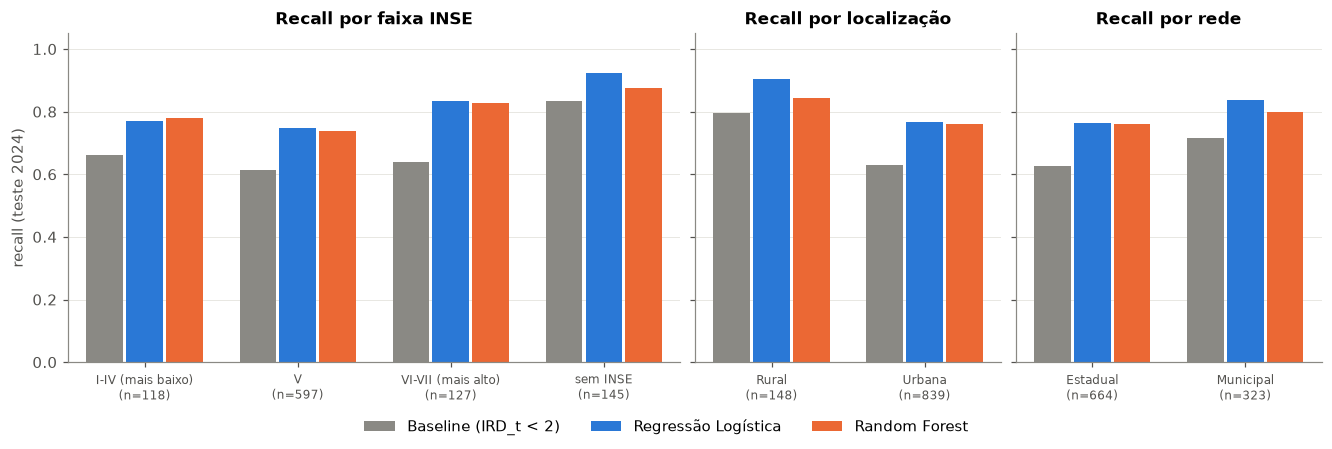

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained",
                         gridspec_kw={"width_ratios": [4, 2, 2]})
for ax, (k, t) in zip(axes, tabs.items()):
    x = np.arange(len(t)); w = 0.26
    for i, n in enumerate(NOMES):
        ax.bar(x + (i - 1) * w, t[n], w - 0.02, color=COR[n], label=n)
    ax.set_xticks(x, [f"{g}\n(n={int(c)})" for g, c in zip(t.index, t["em risco (n)"])], fontsize=8)
    ax.set(title=f"Recall por {k.replace('localizacao', 'localização')}", ylim=(0, 1.05),
           xlim=(-0.5, len(t) - 0.5)); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("recall (teste 2024)")
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, loc="outside lower center")
plt.show()

### 9.1 Como o painel usaria o modelo: risco por município
Exemplo da saída que alimenta o mapa do Radar Docente: o **número de escolas em alerta para 2025** por município (com os dados de 2024), ao lado de quantos alertas se confirmaram e de quantas escolas de fato entraram em baixa regularidade. A contagem de alertas é usada no lugar da soma das probabilidades porque o `class_weight="balanced"` infla as probabilidades: elas servem para **ordenar** o risco, não como frequência esperada.

In [ ]:
MODELO_ESCOLHIDO = "Random Forest"
radar = teste.assign(alerta=pred_te[MODELO_ESCOLHIDO])
radar["alerta_correto"] = radar["alerta"] * radar[ALVO]
mun = (radar.groupby("no_municipio")
       .agg(escolas=("co_escola", "size"), alertas=("alerta", "sum"),
            alertas_corretos=("alerta_correto", "sum"), em_risco_real_2025=(ALVO, "sum"))
       .assign(pct_escolas_em_alerta=lambda d: d["alertas"] / d["escolas"] * 100)
       .sort_values(["alertas", "pct_escolas_em_alerta"], ascending=False))
print(f"Modelo: {MODELO_ESCOLHIDO} | {int(radar['alerta'].sum()):,} alertas em "
      f"{(mun['alertas'] > 0).sum()} de {len(mun)} municípios")
mun.head(15)

Modelo: Random Forest | 1,133 alertas em 272 de 645 municípios


,escolas,alertas,alertas_corretos,em_risco_real_2025,pct_escolas_em_alerta
no_municipio,,,,,
São Paulo,1640,75,59,102,4.573
Taubaté,74,37,26,29,50.000
Ribeirão Preto,103,33,26,31,32.039
Guarulhos,289,33,21,27,11.419
São José dos Campos,107,25,21,24,23.364
Mogi das Cruzes,146,23,15,19,15.753
Campinas,208,23,16,26,11.058
Sorocaba,143,17,9,13,11.888
Ilhabela,26,16,13,15,61.538


## 10. Conclusão: qual modelo usar

| Teste 2024 → 2025 | Precision | Recall | F1 | PR-AUC | Escolas em risco encontradas (VP) | Falsos alertas (FP) |
|---|---|---|---|---|---|---|
| Baseline (IRD_t < 2) | **0,77** | 0,66 | 0,71 | — | 646 de 987 | **194** |
| Regressão Logística | 0,65 | **0,79** | 0,71 | 0,78 | **778 de 987** | 416 |
| **Random Forest** | 0,67 | 0,77 | **0,72** | **0,80** | 764 de 987 | 369 |

**Modelo escolhido: Random Forest (limiar 0,52, definido na validação cruzada do treino).**

1. **Supera o baseline na métrica principal.** O recall da classe 1 sobe de 0,66 para 0,77: **118 escolas em risco a mais** são encontradas um ano antes (764 contra 646), e o F1 também melhora (0,721 contra 0,707). O custo são **175 alertas falsos a mais** (369 contra 194), ou seja, cerca de 1,5 alerta extra para cada escola em risco a mais encontrada.
2. **O custo do erro favorece o recall.** Um **falso negativo** é uma escola que entra no ano letivo com o quadro docente desestruturado sem que a secretaria tenha agido: são aulas vagas e falta de continuidade para os alunos durante o ano inteiro. Um **falso alerta** custa uma checagem do quadro da escola ou um incentivo de permanência aplicado onde talvez não fosse necessário. Como o falso negativo é muito mais caro, trocar ~1,5 alerta extra por uma escola em risco a mais encontrada é um bom negócio.
3. **Contra a Regressão Logística**, o recall é próximo (a RF encontra 14 escolas em risco a menos, 764 contra 778), mas a RF emite **47 alertas falsos a menos**, tem F1 maior (0,721 contra 0,713) e o **melhor PR-AUC (0,80)**, ou seja, ordena melhor as escolas por risco em qualquer limiar. Na auditoria de viés, a RF também tem a **menor diferença de recall entre as redes estadual e municipal** (0,76 contra 0,80; na LR, 0,77 contra 0,84) e entre as faixas de INSE mais baixa e mais alta (0,78 contra 0,83; na LR, 0,77 contra 0,84). A Regressão Logística continua útil como **modelo de apoio para explicar** os resultados: seus coeficientes mostram a direção de cada efeito (seção 8.5).
4. **Modo de alta sensibilidade.** Se a secretaria tiver capacidade de atender mais escolas, basta baixar o limiar da RF para 0,32. O recall chega a **0,88** (cerca de 873 de 987 escolas em risco), com precisão de 0,52 (1.683 alertas, ~15% das escolas). O modelo permite escolher esse ponto conforme o orçamento. A regra fixa do baseline não permite.

## 11. Texto analítico

### Escolhas feitas
- **Alvo binário na faixa oficial do INEP (IRD < 2).** É comunicável ("baixa regularidade" é a linguagem que o gestor já usa) e acionável. Prever o valor exato do IRD seria menos útil para a decisão.
- **Divisão temporal** (treino 2022–2023, teste 2024 → 2025) e **`GroupKFold` por escola** na validação. Simulam o uso real e evitam que a mesma escola apareça no treino e na validação.
- **Pré-processamento dentro do `Pipeline`**, com distinção entre ausente **estrutural** (etapa não oferecida → constante 0 + flag) e ausente **aleatório** (mediana do treino).
- **Limiar escolhido no treino** (*out-of-fold*), nunca no teste. O teste foi usado uma única vez.
- **INSE fora das features.** Não é anual e evita que o modelo aprenda a usar a pobreza da escola como atalho. Ele entra só na auditoria.

### O que os resultados mostram, e o que não mostram
- **A trajetória do próprio IRD domina.** `ird_t`, `ird_t_1` e `delta_ird` concentram quase toda a importância. AFD, IED, ICG, ATU, rendimento e o contexto municipal (`pct_baixa_mun_t`) contribuem muito pouco (importância por permutação ≈ 0). O abandono no Fundamental, mantido de propósito, também não acrescentou informação. **Com os indicadores públicos disponíveis, a instabilidade futura é explicada principalmente pela instabilidade recente**, e não pelas condições de trabalho ou de rendimento observáveis.
- **O ganho sobre o baseline é real, mas modesto.** Na curva precisão × recall, o ponto do baseline fica **sobre** as curvas dos modelos: com o mesmo recall, os modelos não são mais precisos que a regra simples. O valor dos modelos está em: (a) **encontrar escolas que ainda estão acima de 2, mas em queda** (120 das 341 que caem, 35%, contra 0% do baseline); e (b) gerar um **ranking contínuo de risco**, que permite escolher quantas escolas atender.
- **Acurácia não serve como métrica aqui.** Todos os modelos, inclusive o baseline, ficam em ~0,95, porque 91% das escolas não estão em risco.
- **A diferença entre os dois modelos é pequena e instável.** RF e LR ficam muito próximos em todas as métricas. Pequenas mudanças nos dados ou no limiar podem inverter qual deles tem o maior recall. Por isso a escolha leva em conta também o PR-AUC (desempenho em todos os limiares) e a auditoria de viés, e não um único número.

### Limitações
- **O IRD mede estabilidade, não saídas.** Uma escola nova ou em expansão (que contrata muitos professores) tem IRD baixo sem ter problema de rotatividade. Escolas sem IRD em *t-1* (novas) têm o lag imputado.
- **Janelas sobrepostas.** O IRD de *t+1* e o de *t* compartilham 4 dos 5 anos da janela, o que explica a força do baseline e limita o quanto qualquer modelo consegue melhorar.
- **Poucos anos e mudança de tendência.** São só dois anos-base de treino, e a prevalência do alvo vem subindo (5,7% → 7,7% → 9,0%). O limiar e o modelo precisam ser **reajustados todo ano** quando o INEP publicar dados novos.
- **Probabilidades não calibradas.** O `class_weight="balanced"` infla as probabilidades. Elas servem para ordenar escolas por risco, não para estimar contagens. Para isso seria necessária uma calibração (`CalibratedClassifierCV`).
- **Faltam variáveis importantes:** a proporção de **professores temporários** (vínculo funcional, disponível no Censo Escolar por docente), concursos e remunerações (o dado mais recente de remuneração é de 2021) e a distância ou o deslocamento até a escola. É provável que essas variáveis tenham mais poder preditivo que os indicadores usados.
- **Universo restrito** a escolas com Ensino Fundamental e/ou Médio (turmas ou rendimento na etapa) das redes municipal e estadual de SP. Creches, EMEIs e escolas federais ficam fora, inclusive do cálculo de `pct_baixa_mun_t`.

### Vieses que podem prejudicar grupos
A auditoria (seção 9) olhou o recall da Random Forest por grupo:
- **Rede estadual: o principal ponto de atenção.** É a rede com **maior taxa de risco** (12,5%, contra 5,7% na municipal) e, mesmo assim, tem **recall menor** (0,76 contra 0,80). Em números absolutos, cerca de 160 escolas estaduais em risco não são avisadas. A RF reduz essa diferença em relação à LR, mas não a elimina. Mitigação: usar um **limiar por rede** ou acompanhar o recall da rede estadual separadamente.
- **Nível socioeconômico.** O recall nas escolas de INSE mais baixo (0,78) fica abaixo do das de INSE mais alto (0,83), e a faixa intermediária (V), que concentra a maioria das escolas, tem o menor recall (0,74). A diferença está na **direção indesejada**: o modelo encontra proporcionalmente menos escolas em risco entre as mais pobres do que entre as mais ricas. Os grupos extremos são pequenos (118 e 127 escolas em risco), então a diferença pode ser ruído, mas precisa ser monitorada a cada ano.
- **Escolas sem INSE**, que não participaram do Saeb (em geral pequenas, rurais ou multisseriadas), têm a **maior taxa de risco** (17,5%). O modelo as encontra bem (recall 0,88), mas elas são um **ponto cego da auditoria**: não dá para dizer em qual faixa socioeconômica estão.
- **Zona rural.** O recall é alto (0,85 contra 0,76 na urbana), mas isso vem junto com mais alertas nessas escolas. É preciso evitar que o "rótulo de risco" vire estigma ou justificativa para fechar escolas rurais. Já nas escolas urbanas, que são a maioria das escolas em risco (839 de 987), o modelo deixa passar quase 1 em cada 4.
- **Uso indevido.** O Radar indica **onde apoiar**, não onde punir. Usá-lo para avaliar diretores ou cortar recursos inverteria o objetivo e penalizaria justamente as escolas mais vulneráveis.

### Contribuição para a decisão
Com dados públicos e reprodutíveis do INEP, o Radar Docente entrega à secretaria uma **lista priorizada de escolas e municípios** (seção 9.1) com cerca de **um ano de antecedência** em relação ao IRD oficial. No teste, a ferramenta encontrou **mais de 3 de cada 4 escolas** que entraram em baixa regularidade, com **67% dos alertas corretos**, inclusive **120 escolas que o indicador atual ainda mostrava como estáveis**. Isso permite planejar concursos, a alocação de efetivos e incentivos de permanência **antes** do ano letivo, para que o aluno de escola pública não comece o ano sem professor.

*O INEP mostra onde o problema já aconteceu; o Radar mostra onde vai acontecer.*

## 12. Anexo: saída para o dashboard do pitch

Esta seção **não faz parte da avaliação do modelo**. Ela gera os arquivos que alimentam o protótipo do Radar Docente com números reais:

- **Previsão para 2026:** o modelo escolhido é aplicado às features de **2025** (IRD de 2025, lag de 2024 e indicadores de 2025). Usamos **o mesmo modelo avaliado na seção 8** (treinado em 2022–2023), para que as métricas reportadas valham também para essas previsões. Em produção, o modelo seria re-treinado incluindo o ano-base 2024.
- **Classes de risco:** com prevalência em torno de 9%, as probabilidades ficam concentradas perto de 0 (e o `class_weight` desloca a escala), então terços fixos não fazem sentido. Os cortes são definidos **no treino (*out-of-fold*)**:
  - **alto:** acima do limiar operacional do modelo (o mesmo dos alertas da seção 8);
  - **médio:** entre esse limiar e o limiar que dá **recall ≥ 95%** no treino;
  - **baixo:** o resto.

In [ ]:
prev25 = pd.read_csv(DATA / "base_previsao_2025.csv", dtype={"co_escola": str, "co_municipio": str})
modelo_final = modelos[MODELO_ESCOLHIDO].best_estimator_

CORTE_ALTO = limiar[MODELO_ESCOLHIDO]
CORTE_MEDIO = limiar_para_recall(y_tr, oof[MODELO_ESCOLHIDO], alvo_recall=0.95)
print(f"Modelo: {MODELO_ESCOLHIDO} | corte alto ≥ {CORTE_ALTO:.2f} | corte médio ≥ {CORTE_MEDIO:.2f}")


def classe_risco(p):
    p = pd.Series(p, dtype=float)
    return pd.Series(np.select([p >= CORTE_ALTO, p >= CORTE_MEDIO], ["alto", "médio"], "baixo"),
                     index=p.index).where(p.notna())


conf = pd.DataFrame({"classe prevista para 2025": classe_risco(proba_te[MODELO_ESCOLHIDO]),
                     "alvo": y_te.values})
(conf.groupby("classe prevista para 2025")["alvo"]
     .agg(escolas="size", com_IRD_abaixo_de_2="sum", taxa_real="mean")
     .reindex(["alto", "médio", "baixo"]))

Modelo: Random Forest | corte alto ≥ 0.52 | corte médio ≥ 0.10


,escolas,com_IRD_abaixo_de_2,taxa_real
classe prevista para 2025,,,
alto,1133,764,0.674
médio,1437,180,0.125
baixo,8370,43,0.005


### 12.1 `radar_escolas.csv`: uma linha por escola × ano (2022 a 2026)

- **2022 a 2024 (`observado`):** IRD e indicadores daquele ano, com os **valores originais** (etapa não oferecida fica vazia, não 0).
- **2025 (`observado+previsto`):** valores observados, mais `prob_risco` e `classe_risco` previstos com as features de 2024 (o conjunto de teste), para mostrar "previsto vs real".
- **2026 (`previsto`):** só `prob_risco` e `classe_risco`. **O modelo prevê a probabilidade de IRD < 2, não o valor do IRD**, então não existe "IRD 2026".
- Não há previsões para 2023 e 2024, porque essas escolas estavam no treino.

A tabela abaixo confere o arquivo: quantas escolas há em cada ano e tipo de linha, por classe de risco prevista. Os anos 2022 a 2024 ficam todos em "sem previsão". Em 2025, umas poucas escolas só têm dados observados, porque não estavam no conjunto de teste.

In [ ]:
DASH = Path("../data/processed")
DASH.mkdir(exist_ok=True)

CAD = ["co_escola", "no_escola", "co_municipio", "no_municipio", "rede", "localizacao",
       "tem_fundamental", "tem_medio"]
IND = ["ird_t", "pct_baixa_mun_t"] + [c for par in zip(FUN, MED) for c in par] + ["icg"]
SAIDA = {"ano_base": "ano", "no_escola": "nome", "no_municipio": "municipio", "ird_t": "ird",
         "pct_baixa_mun_t": "pct_baixa_mun"}

sem_2025 = (teste.loc[~teste["co_escola"].isin(prev25["co_escola"]), CAD[:6] + ["ird_t1"]]
            .rename(columns={"ird_t1": "ird_t"}).assign(ano_base=2025))
observado = pd.concat([base[["ano_base"] + CAD + IND], prev25[["ano_base"] + CAD + IND], sem_2025],
                      ignore_index=True).assign(tipo="observado")
previsto_2025 = teste[["co_escola"]].assign(ano_base=2025, prob_risco=proba_te[MODELO_ESCOLHIDO])
observado = observado.merge(previsto_2025, on=["co_escola", "ano_base"], how="left")
observado.loc[observado["prob_risco"].notna(), "tipo"] = "observado+previsto"

previsto_2026 = prev25[CAD].assign(
    ano_base=2026, tipo="previsto",
    prob_risco=modelo_final.predict_proba(prev25[FEATURES])[:, 1])

radar = pd.concat([observado, previsto_2026], ignore_index=True)
radar["classe_risco"] = classe_risco(radar["prob_risco"])
radar = (radar.rename(columns=SAIDA)
         [["ano", "tipo"] + [SAIDA.get(c, c) for c in CAD + IND] + ["prob_risco", "classe_risco"]]
         .sort_values(["co_escola", "ano"]).reset_index(drop=True))
radar.to_csv(DASH / "radar_escolas.csv", index=False, encoding="utf-8")

print(f"radar_escolas.csv: {len(radar):,} linhas, {radar['co_escola'].nunique():,} escolas")
print("Conferência: nº de escolas por ano/tipo de linha e classe de risco prevista")
(pd.crosstab([radar["ano"], radar["tipo"]], radar["classe_risco"].fillna("sem previsão"),
             rownames=["ano", "tipo de linha"], colnames=["classe de risco"])
   .reindex(columns=["alto", "médio", "baixo", "sem previsão"], fill_value=0)
   .assign(total=lambda d: d.sum(axis=1)))

radar_escolas.csv: 54,850 linhas, 11,167 escolas
Conferência: nº de escolas por ano/tipo de linha e classe de risco prevista


classe de risco          alto  médio  baixo  sem previsão  total
ano  tipo de linha                                              
2022 observado              0      0      0         10997  10997
2023 observado              0      0      0         10972  10972
2024 observado              0      0      0         10940  10940
2025 observado              0      0      0            50     50
     observado+previsto  1133   1437   8370             0  10940
2026 previsto            1338   1631   7982             0  10951

### 12.2 `radar_municipios_2026.csv`

Número de escolas, número e % em risco alto e médio, IRD médio de 2025 e as **coordenadas da sede do município** (`latitude`, `longitude`, de `data/municipios.csv`), para o mapa de bolhas do painel. A ligação é feita pelo código IBGE (`co_municipio`).

radar_municipios_2026.csv: 645 municípios
2026: 1,338 escolas em risco alto em 268 municípios


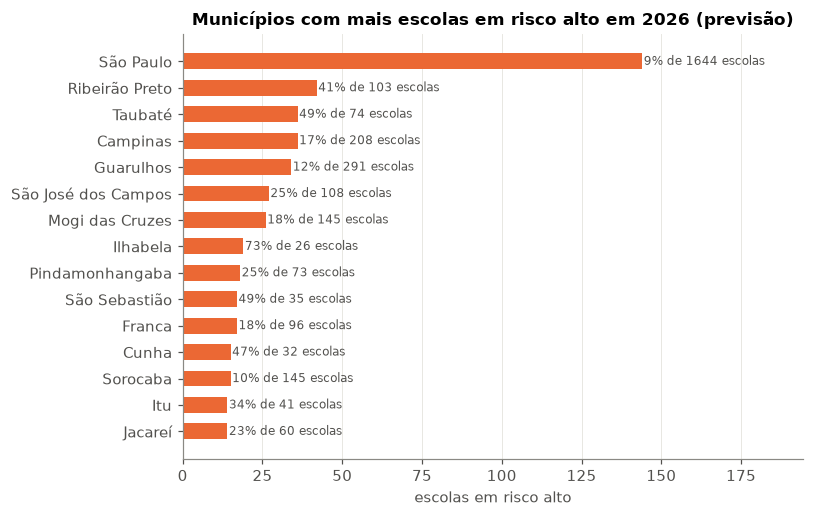

,co_municipio,municipio,escolas,risco_alto,risco_medio,pct_risco_alto,pct_risco_medio,ird_medio_2025,latitude,longitude
562,3550308,São Paulo,1644,144,215,8.759,13.078,2.832,-23.533,-46.639
487,3543402,Ribeirão Preto,103,42,41,40.777,39.806,2.200,-21.170,-47.810
604,3554102,Taubaté,74,36,26,48.649,35.135,2.175,-23.010,-45.559
108,3509502,Campinas,208,36,50,17.308,24.038,2.543,-22.905,-47.066
212,3518800,Guarulhos,291,34,41,11.684,14.089,2.591,-23.454,-46.533
557,3549904,São José dos Campos,108,27,26,25.000,24.074,2.374,-23.190,-45.884
343,3530607,Mogi das Cruzes,145,26,23,17.931,15.862,2.703,-23.521,-46.185
232,3520400,Ilhabela,26,19,6,73.077,23.077,1.942,-23.779,-45.355
427,3538006,Pindamonhangaba,73,18,10,24.658,13.699,2.695,-22.925,-45.461
566,3550704,São Sebastião,35,17,15,48.571,42.857,2.177,-23.795,-45.414


In [ ]:
coords = (pd.read_csv(DATA / "municipios.csv", dtype={"codigo_ibge": str})
          .rename(columns={"codigo_ibge": "co_municipio"})[["co_municipio", "latitude", "longitude"]])

r26 = radar[radar["ano"] == 2026]
ird25 = radar[radar["ano"] == 2025].groupby("co_municipio")["ird"].mean().rename("ird_medio_2025")
mun26 = (r26.groupby(["co_municipio", "municipio"])
         .agg(escolas=("co_escola", "size"),
              risco_alto=("classe_risco", lambda s: (s == "alto").sum()),
              risco_medio=("classe_risco", lambda s: (s == "médio").sum()))
         .assign(pct_risco_alto=lambda d: d["risco_alto"] / d["escolas"] * 100,
                 pct_risco_medio=lambda d: d["risco_medio"] / d["escolas"] * 100)
         .reset_index().merge(ird25, on="co_municipio", how="left")
         .merge(coords, on="co_municipio", how="left")
         .sort_values(["risco_alto", "pct_risco_alto"], ascending=False))
assert mun26[["latitude", "longitude"]].notna().all().all()
mun26.to_csv(DASH / "radar_municipios_2026.csv", index=False, encoding="utf-8")

print(f"radar_municipios_2026.csv: {len(mun26)} municípios")
print(f"2026: {int(mun26['risco_alto'].sum()):,} escolas em risco alto em "
      f"{(mun26['risco_alto'] > 0).sum()} municípios")

top = mun26.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.barh(top["municipio"], top["risco_alto"], color=LARANJA, height=0.6)
for b, (n, pct) in zip(bars, top[["escolas", "pct_risco_alto"]].values):
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2,
            f"{pct:.0f}% de {int(n)} escolas", va="center", fontsize=8, color=TEXTO_2)
ax.set(title="Municípios com mais escolas em risco alto em 2026 (previsão)",
       xlabel="escolas em risco alto")
ax.set_xlim(0, top["risco_alto"].max() * 1.35); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
mun26.head(10)